In [4]:
import pandas as pd
import numpy as np

csv_path = "../results/mcts_pi_svgp_cs_extract_YasMarina_10/traj_config_mcts_dpw_pi_svgp_cpp_cs_extract_s42_YasMarina_10_20260219_110439.csv"

df = pd.read_csv(csv_path, comment="#")
print(f"Shape: {df.shape}")
df = df.dropna(subset=['Aa_action_list'])
df = df.drop(['pred_vx', 'pred_vy', 'pred_omega'], axis=1)

# Convert semicolon-separated action list strings to numpy arrays
df['Aa_action_list'] = df['Aa_action_list'].apply(lambda s: np.array([float(x) for x in s.split(';')]))
df['Asv_action_list'] = df['Asv_action_list'].apply(lambda s: np.array([float(x) for x in s.split(';')]))

print(f"Example Aa_action_list (step 0): {df['Aa_action_list'].iloc[0]}")
print(f"Type: {type(df['Aa_action_list'].iloc[0])}, Length: {len(df['Aa_action_list'].iloc[0])}")

Shape: (3048, 16)
Example Aa_action_list (step 0): [ 9.449311  8.345898  7.453466  9.252404  5.442439 -1.647828  7.205273
  8.775101]
Type: <class 'numpy.ndarray'>, Length: 8


In [5]:
df.columns

Index(['S_x', 'S_y', 'S_delta', 'S_vel', 'S_psi', 'S_omega', 'S_beta', 'A_a',
       'A_sv', 'Aa_action_list', 'Asv_action_list', 'C_alpha',
       'C_alpha_smooth'],
      dtype='object')

In [6]:
# required row

row = df.iloc[20]

In [7]:
row

S_x                                                         4.246556
S_y                                                         0.706554
S_delta                                                    -0.008689
S_vel                                                       7.093549
S_psi                                                       0.115299
S_omega                                                    -0.513699
S_beta                                                      0.010515
A_a                                                         5.152157
A_sv                                                       -1.436311
Aa_action_list     [5.152157, 9.204883, 2.158556, 7.289248, 1.298...
Asv_action_list    [-1.436311, 1.461619, 1.981736, -0.681387, -1....
C_alpha                                                    97.630125
C_alpha_smooth                                             99.457205
Name: 26, dtype: object

In [8]:
import torch
import json
from sklearn.preprocessing import StandardScaler

# ── Load PI-SVGP model ──────────────────────────────────────────────────────
# model_path = "../models/pi_svgp_mcts_data/mcts_svgp_best_params.npz"
model_path = "../models/pi_svgp_mcts_fixed/mcts_svgp_fixed.npz"

data = np.load(model_path, allow_pickle=False)

# Kernel hyperparams
theta = torch.tensor(data['model__theta_opt'], dtype=torch.float64)

# Inducing points (augmented: input + latent)
Zx = torch.tensor(data['model__Zx_opt'], dtype=torch.float64)   # (M, 6)
Zh = torch.tensor(data['model__Zh_opt'], dtype=torch.float64)   # (M, 2)
Z_aug = torch.cat([Zx, Zh], dim=1)                              # (M, 8)
M = Z_aug.shape[0]

# Variational inducing means and log-stds
m_opt = torch.tensor(data['model__m_opt'], dtype=torch.float64)            # (M, 9)
m_logstd = torch.tensor(data['model__m_logstd_opt'], dtype=torch.float64)  # (M, 9)

# Output bias
output_bias = torch.tensor(data['model__output_bias_opt'], dtype=torch.float64)  # (9,)

# Task latent means (for C_alpha interpolation)
h_mu_all = data['model__h_mu_opt']  # (3, 2)

# Input scaler
xmean = torch.tensor(data['xscaler__mean'], dtype=torch.float64)
xscale = torch.tensor(data['xscaler__scale'], dtype=torch.float64)

# ── Precompute kernel matrices ───────────────────────────────────────────────
def rbf_ard_kernel(X, Z, th):
    ls, sigma = th[:-1], th[-1]
    Xs, Zs = X / ls, Z / ls
    dist = (Xs**2).sum(1, keepdim=True) + (Zs**2).sum(1, keepdim=True).T - 2*Xs@Zs.T
    return (sigma**2) * torch.exp(-0.5 * dist)

K_mm = rbf_ard_kernel(Z_aug, Z_aug, theta) + torch.eye(M, dtype=torch.float64) * 1e-6
K_mm_inv = torch.linalg.inv(K_mm)
alpha_gp = K_mm_inv @ m_opt  # (M, 9) for fast mean

# ── C_alpha → latent interpolation ───────────────────────────────────────────
c_alpha_anchors = np.array([104.89, 86.42, 49.47])
h_anchors = h_mu_all[:3]
calpha_slopes = np.zeros(h_anchors.shape[1])
calpha_intercepts = np.zeros(h_anchors.shape[1])
for d in range(h_anchors.shape[1]):
    calpha_slopes[d], calpha_intercepts[d] = np.polyfit(c_alpha_anchors, h_anchors[:, d], 1)

def interpolate_hp_mu(c_alpha):
    return torch.tensor(calpha_slopes * c_alpha + calpha_intercepts, dtype=torch.float64)

# ── Constants ────────────────────────────────────────────────────────────────
POSITIVE_IDX = [0, 1, 2, 4, 5, 6]
PACEJKA_NAMES = ["Bf", "Cf", "Df", "Ef", "Br", "Cr", "Dr", "Er", "Frx"]
VP = dict(lf=0.15875, lr=0.17145, mass=3.74, Iz=0.04712,
          s_min=-0.4189, s_max=0.4189, sv_min=-3.2, sv_max=3.2,
          v_switch=7.319, a_max=9.51, v_min=-5.0, v_max=20.0)
BASE_DT = 0.02
DT = 0.04

print(f"Model loaded: M={M}, Z_aug={Z_aug.shape}, m_logstd={m_logstd.shape}")

Model loaded: M=50, Z_aug=torch.Size([50, 8]), m_logstd=torch.Size([50, 9])


In [9]:
# ── GP helpers for delta method ───────────────────────────────────────────────

def extract_features(state_7, action_2, dt=BASE_DT):
    """state_7: [x,y,delta,v,psi,omega,beta], action_2: [accel, steer_vel]
    -> features: (6,) [VX, VY, YAW_RATE, STEERING_FB, THROTTLE_CMD, STEERING_CMD]"""
    v, delta, omega, beta = state_7[3], state_7[2], state_7[5], state_7[6]
    accel, sv = action_2[0], action_2[1]
    return torch.tensor([
        v * torch.cos(beta), v * torch.sin(beta), omega,
        delta, accel * dt, sv * dt,
    ], dtype=torch.float64)


def gp_predict_mean_and_var(features_1d, hp_mu):
    """GP posterior mean (9,) and variance (9,) in raw (pre-constraint) space."""
    feat_norm = (features_1d.unsqueeze(0) - xmean) / xscale
    X_aug = torch.cat([feat_norm, hp_mu.unsqueeze(0)], dim=1)  # (1, 8)

    K_nm = rbf_ard_kernel(X_aug, Z_aug, theta)  # (1, M)
    al = K_nm @ K_mm_inv                         # (1, M)

    raw_mean = (al @ m_opt).squeeze(0) + output_bias  # (9,)

    sigma2 = theta[-1] ** 2
    reduction = (al * K_nm).sum()
    var = torch.zeros(9, dtype=torch.float64)
    for p in range(9):
        S_p = torch.exp(2.0 * m_logstd[:, p])
        var[p] = sigma2 - reduction + (al.squeeze(0)**2 * S_p).sum()

    return raw_mean, var


def constrain_pacejka(raw):
    """Softplus on Bf,Cf,Df,Br,Cr,Dr. Works on (9,) or (N,9)."""
    out = raw.clone()
    if raw.dim() == 1:
        for i in POSITIVE_IDX:
            out[i] = torch.nn.functional.softplus(raw[i])
    else:
        out[:, POSITIVE_IDX] = torch.nn.functional.softplus(raw[:, POSITIVE_IDX])
    return out

print("GP helper functions defined.")

GP helper functions defined.


In [10]:
# ── Delta method: full state covariance propagation ──────────────────────────
#
# At each substep we linearize the state transition around (mean_state, GP_mean):
#   Cov_{t+1} = J_s @ Cov_t @ J_s^T  +  J_θ @ diag(GP_var) @ J_θ^T
#
# where J_s = d(next_state)/d(state)      (7x7)  — propagates prior uncertainty
#       J_θ = d(next_state)/d(raw_params)  (7x9)  — injects new GP uncertainty


def full_state_transition(state_7, raw_params_9, action_2, dt=BASE_DT):
    """Differentiable: (7-state, 9-raw-pacejka, action) -> 7-next-state.
    
    Combines: constrain Pacejka → tire forces → body dynamics → kinematic update.
    """
    x, y, delta, v, psi, omega, beta = (
        state_7[0], state_7[1], state_7[2], state_7[3],
        state_7[4], state_7[5], state_7[6],
    )
    accel, sv = action_2[0], action_2[1]

    # Body-frame velocities from state
    VX = v * torch.cos(beta)
    VY = v * torch.sin(beta)
    YR = omega
    steer = delta + sv * dt

    # Constrain Pacejka params
    constrained = constrain_pacejka(raw_params_9)
    Bf, Cf, Df, Ef, Br, Cr, Dr, Er, Frx = constrained

    # Pacejka tire forces
    alphaf = steer - torch.atan2(VP['lf'] * YR + VY, torch.abs(VX))
    alphar = torch.atan2(VP['lr'] * YR - VY, torch.abs(VX))
    Ffy = Df * torch.sin(Cf * torch.atan(Bf * alphaf - Ef * (Bf * alphaf - torch.atan(Bf * alphaf))))
    Fry = Dr * torch.sin(Cr * torch.atan(Br * alphar - Er * (Br * alphar - torch.atan(Br * alphar))))

    # Body-frame dynamics
    next_VX = VX + dt * ((1 / VP['mass']) * (Frx - Ffy * torch.sin(steer)) + VY * YR)
    next_VY = VY + dt * ((1 / VP['mass']) * (Fry + Ffy * torch.cos(steer)) - VX * YR)
    next_YR = YR + dt * (1 / VP['Iz']) * (Ffy * VP['lf'] * torch.cos(steer) - Fry * VP['lr'])

    # Kinematic update
    omega_pred = next_YR
    beta_pred = torch.atan2(next_VY, next_VX + 1e-8)

    return torch.stack([
        x + dt * v * torch.cos(beta_pred + psi),
        y + dt * v * torch.sin(beta_pred + psi),
        delta + dt * sv,
        v + dt * accel,
        psi + dt * omega_pred,
        omega_pred,
        beta_pred,
    ])


def delta_substep(mean_state, cov, action_2, hp_mu, dt=BASE_DT):
    """One substep: propagate mean state + 7x7 covariance via Jacobians.
    
    Returns: (next_mean_state, next_cov)
    """
    # GP prediction at the current mean state
    features = extract_features(mean_state, action_2, dt)
    raw_mean, raw_var = gp_predict_mean_and_var(features, hp_mu)

    # Detached copies for Jacobian computation
    s = mean_state.detach().clone().requires_grad_(True)
    r = raw_mean.detach().clone().requires_grad_(True)
    a = action_2.detach()

    # J_s: how next_state changes with current state (7x7)
    J_state = torch.autograd.functional.jacobian(
        lambda s_: full_state_transition(s_, r, a, dt), s
    )  # (7, 7)

    # J_θ: how next_state changes with raw Pacejka params (7x9)
    J_theta = torch.autograd.functional.jacobian(
        lambda r_: full_state_transition(s, r_, a, dt), r
    )  # (7, 9)

    # Propagate mean deterministically
    next_mean = full_state_transition(mean_state.detach(), raw_mean.detach(), a, dt)

    # Propagate covariance:
    #   prior uncertainty through state Jacobian + new GP uncertainty through param Jacobian
    next_cov = J_state @ cov @ J_state.T + J_theta @ torch.diag(raw_var) @ J_theta.T

    return next_mean.detach(), next_cov.detach()


def rollout_row_state_delta(row, c_alpha_override=None):
    """Delta method rollout: propagate mean + 7x7 covariance through the action sequence.
    
    Args:
        c_alpha_override: If provided, use this C_alpha instead of row.C_alpha_smooth.
    
    Returns:
        dict with 'state_means' (n+1, 7) and 'state_vars' (n+1, 7) — diagonal of covariance.
    """
    state0 = torch.tensor([row.S_x, row.S_y, row.S_delta, row.S_vel,
                           row.S_psi, row.S_omega, row.S_beta], dtype=torch.float64)
    c_alpha = c_alpha_override if c_alpha_override is not None else row.C_alpha_smooth
    hp_mu = interpolate_hp_mu(c_alpha)
    accels, steers = row.Aa_action_list, row.Asv_action_list
    n_actions = min(len(accels), len(steers))

    mean_state = state0.clone()
    cov_state = torch.zeros(7, 7, dtype=torch.float64)

    state_means = [state0.numpy().copy()]
    state_vars = [np.zeros(7)]

    for i in range(n_actions):
        action = torch.tensor([accels[i], steers[i]], dtype=torch.float64)
        # 2 substeps of BASE_DT per action (matching the MC version)
        mean_state, cov_state = delta_substep(mean_state, cov_state, action, hp_mu, BASE_DT)
        mean_state, cov_state = delta_substep(mean_state, cov_state, action, hp_mu, BASE_DT)
        state_means.append(mean_state.numpy().copy())
        state_vars.append(torch.diag(cov_state).clamp(min=0).numpy().copy())

    return {
        "state_means": np.array(state_means),  # (n_actions+1, 7)
        "state_vars": np.array(state_vars),     # (n_actions+1, 7)
    }

print("Delta method functions defined: full_state_transition, delta_substep, rollout_row_state_delta")

Delta method functions defined: full_state_transition, delta_substep, rollout_row_state_delta


In [11]:
import time

STATE_NAMES = ["x", "y", "delta", "v", "psi", "omega", "beta"]

t0 = time.perf_counter()
res_delta = rollout_row_state_delta(row)
t_delta = time.perf_counter() - t0

n_steps = res_delta["state_means"].shape[0]
print(f"=== Full State Distribution (Delta Method) — {t_delta*1000:.1f} ms ===\n")
print(f"{'Step':>4}  " + "  ".join(f"{n:>8} {'±std':>8}" for n in STATE_NAMES))
print("-" * (6 + 18 * 7))
for i in range(n_steps):
    m = res_delta["state_means"][i]
    s = np.sqrt(np.maximum(res_delta["state_vars"][i], 0))
    vals = "  ".join(f"{m[j]:8.4f} {s[j]:8.4f}" for j in range(7))
    print(f"{i:4d}  {vals}")

=== Full State Distribution (Delta Method) — 147.3 ms ===

Step         x     ±std         y     ±std     delta     ±std         v     ±std       psi     ±std     omega     ±std      beta     ±std
------------------------------------------------------------------------------------------------------------------------------------
   0    4.2466   0.0000    0.7066   0.0000   -0.0087   0.0000    7.0935   0.0000    0.1153   0.0000   -0.5137   0.0000    0.0105   0.0000
   1    4.5299   0.0000    0.7436   0.0000   -0.0661   0.0000    7.2996   0.0000    0.0954   0.0002   -0.5195   0.0082    0.0215   0.0001
   2    4.8235   0.0000    0.7791   0.0001   -0.0077   0.0000    7.6678   0.0000    0.0851   0.0008   -0.1475   0.0196    0.0302   0.0005
   3    5.1290   0.0000    0.8147   0.0001    0.0716   0.0000    7.7542   0.0000    0.0946   0.0012    0.4010   0.0128    0.0292   0.0010
   4    5.4400   0.0000    0.8504   0.0002    0.0443   0.0000    8.0457   0.0000    0.1220   0.0013    0.7276   0.0069

# Plotting code

In [12]:
import sys
sys.path.insert(0, "..")
from src.dynamics.f1tenth_dynamics import F1TenthDynamicsModel
from src.params import VehicleParams
from src.idl_messages import VehicleStateMsg, ControlCmdMsg

print("True dynamics imports loaded.")

True dynamics imports loaded.


In [13]:
import matplotlib.pyplot as plt
from PIL import Image
import yaml
import os
from src.track import Track

def load_trajectory_df(csv_path):
    """Load and preprocess a trajectory CSV."""
    df = pd.read_csv(csv_path, comment="#")
    df = df.dropna(subset=['Aa_action_list'])
    for col in ['pred_vx', 'pred_vy', 'pred_omega']:
        if col in df.columns:
            df = df.drop(col, axis=1)
    df['Aa_action_list'] = df['Aa_action_list'].apply(lambda s: np.array([float(x) for x in s.split(';')]))
    df['Asv_action_list'] = df['Asv_action_list'].apply(lambda s: np.array([float(x) for x in s.split(';')]))
    return df


def load_map_and_track(track_name, friction="10489", maps_dir="../maps"):
    """Load map image, metadata, and track boundaries."""
    map_dir = f"{maps_dir}/{track_name}_{friction}"
    map_img = np.array(
        Image.open(f"{map_dir}/{track_name}_map.png").transpose(Image.FLIP_TOP_BOTTOM)
    ).astype(np.float64)

    with open(f"{map_dir}/{track_name}_map.yaml") as f:
        map_meta = yaml.safe_load(f)
    map_res = map_meta["resolution"]
    orig_x, orig_y = map_meta["origin"][0], map_meta["origin"][1]
    h_px, w_px = map_img.shape[:2]
    extent = [orig_x, orig_x + w_px * map_res, orig_y, orig_y + h_px * map_res]

    centerline_path = f"{map_dir}/{track_name}_centerline.csv"
    track_obj = Track(centerline_path)

    return map_img, extent, track_obj


def plot_svgp_prediction(ax, row, map_img, extent, track_obj,
                         mu=1.0, lane_width=1.1, show_legend=False):
    """Plot a single row's PI-SVGP prediction (delta method) with map, boundaries, and true dynamics.
    
    SVGP uses C_alpha = 100 * mu (not the CSV's C_alpha_smooth).
    True dynamics uses VehicleParams(mu=mu).
    """
    c_alpha = 100.0 * mu
    # c_alpha = 100.0 

    # Delta method state rollout with overridden C_alpha
    res = rollout_row_state_delta(row, c_alpha_override=c_alpha)

    means, varis = res["state_means"], res["state_vars"]
    x_mean, y_mean = means[:, 0], means[:, 1]
    x_std = np.sqrt(np.maximum(varis[:, 0], 0))
    y_std = np.sqrt(np.maximum(varis[:, 1], 0))
    x_upper, y_upper = x_mean + 1000 * x_std, y_mean + 1000 * y_std
    x_lower, y_lower = x_mean - 1000 * x_std, y_mean - 1000 * y_std

    # True dynamics rollout with this mu
    true_vp = VehicleParams(mu=mu)
    true_dyn = F1TenthDynamicsModel(true_vp)
    state = VehicleStateMsg(
        x=row.S_x, y=row.S_y, delta=row.S_delta, v=row.S_vel,
        psi=row.S_psi, omega=row.S_omega, beta=row.S_beta,
    )
    accels, steers = row.Aa_action_list, row.Asv_action_list
    n_actions = min(len(accels), len(steers))
    true_states = [np.array([state.x, state.y, state.delta, state.v,
                             state.psi, state.omega, state.beta])]
    for i in range(n_actions):
        cmd = ControlCmdMsg(acceleration=accels[i], steering_vel=steers[i])
        state = true_dyn.predict_next_state(state, cmd, BASE_DT)
        state = true_dyn.predict_next_state(state, cmd, BASE_DT)
        true_states.append(np.array([state.x, state.y, state.delta, state.v,
                                     state.psi, state.omega, state.beta]))
    true_states = np.array(true_states)

    # Controller corridor
    half_lw = lane_width / 2.0
    ctrl_left = track_obj.centerline + track_obj.normal * half_lw
    ctrl_right = track_obj.centerline - track_obj.normal * half_lw

    # Draw
    ax.imshow(map_img, cmap="gray", origin="lower", extent=extent, alpha=0.5)

    ax.plot(track_obj.left_boundary[:, 0], track_obj.left_boundary[:, 1],
            "-", color="gray", linewidth=0.8, alpha=0.6, label="Track boundary")
    ax.plot(track_obj.right_boundary[:, 0], track_obj.right_boundary[:, 1],
            "-", color="gray", linewidth=0.8, alpha=0.6)

    ax.plot(ctrl_left[:, 0], ctrl_left[:, 1],
            "-", color="red", linewidth=1.0, alpha=0.7, label=f"Controller boundary (lw={lane_width}m)")
    ax.plot(ctrl_right[:, 0], ctrl_right[:, 1],
            "-", color="red", linewidth=1.0, alpha=0.7)

    corridor_x = np.concatenate([x_upper, x_lower[::-1]])
    corridor_y = np.concatenate([y_upper, y_lower[::-1]])
    ax.fill(corridor_x, corridor_y, alpha=0.3, color="steelblue", label="$\pm 2\sigma$ (PI-SVGP delta)")
    ax.plot(x_upper, y_upper, "--", color="steelblue", linewidth=1, alpha=0.6)
    ax.plot(x_lower, y_lower, "--", color="steelblue", linewidth=1, alpha=0.6)

    ax.plot(x_mean, y_mean, "o-", color="steelblue", markersize=5, linewidth=1.5, label="PI-SVGP mean")
    ax.plot(true_states[:, 0], true_states[:, 1], "s-", color="darkorange", markersize=5,
            linewidth=1.5, label=f"True dynamics (mu={mu})")
    ax.plot(x_mean[0], y_mean[0], "*", color="crimson", markersize=14, zorder=5, label="$s_0$")

    pad = 3.0
    ax.set_xlim(min(x_lower.min(), true_states[:, 0].min()) - pad,
                max(x_upper.max(), true_states[:, 0].max()) + pad)
    ax.set_ylim(min(y_lower.min(), true_states[:, 1].min()) - pad,
                max(y_upper.max(), true_states[:, 1].max()) + pad)
    ax.set_xlabel("x [m]", fontsize=13)
    ax.set_ylabel("y [m]", fontsize=13)
    ax.set_aspect("equal")
    ax.grid(True, alpha=0.3)

    if show_legend:
        ax.legend(loc="upper left", fontsize=12)


def plot_svgp_samples(csv_path, track_name, row_indices,
                      mu=1.0489, lane_width=1.1, friction="10489",
                      maps_dir="../maps",
                      save_dir="plot_res_change_mu_cs"):
    """Main entry point: load data, generate plots for given row indices.
    
    SVGP uses C_alpha = 100 * mu, true dynamics uses VehicleParams(mu=mu).
    Variance computed via delta method (Jacobian covariance propagation).
    """
    df = load_trajectory_df(csv_path)
    map_img, extent, track_obj = load_map_and_track(track_name, friction, maps_dir)

    n = len(row_indices)
    fig, axes = plt.subplots(1, n, figsize=(12 * n, 10), squeeze=False)

    for i, idx in enumerate(row_indices):
        row = df.iloc[idx]
        ax = axes[0, i]
        plot_svgp_prediction(ax, row, map_img, extent, track_obj,
                             mu=mu, lane_width=lane_width,
                             show_legend=(i == 0))
        ax.set_title(f"Row {idx} — v={row.S_vel:.1f} m/s, "
                     f"mu={mu}, C_alpha={100*mu:.0f}", fontsize=14)

    fig.suptitle(f"PI-SVGP (Delta Method) vs True Dynamics — {track_name} (mu={mu})",
                 fontsize=18, y=1.02)
    plt.tight_layout()

    if save_dir is not None:
        os.makedirs(save_dir, exist_ok=True)
        rows_str = "_".join(str(r) for r in row_indices)
        fname = f"svgp_delta_{track_name}_mu{mu}_{rows_str}.png"
        save_path = os.path.join(save_dir, fname)
        fig.savefig(save_path, dpi=150, bbox_inches="tight")
        print(f"Saved: {save_path}")

    plt.show()

print("Functions defined: plot_svgp_samples(csv_path, track_name, row_indices, mu=..., ...)")

Functions defined: plot_svgp_samples(csv_path, track_name, row_indices, mu=..., ...)


Saved: plot_res_change_mu_cs/svgp_delta_YasMarina_mu0.2_1240.png


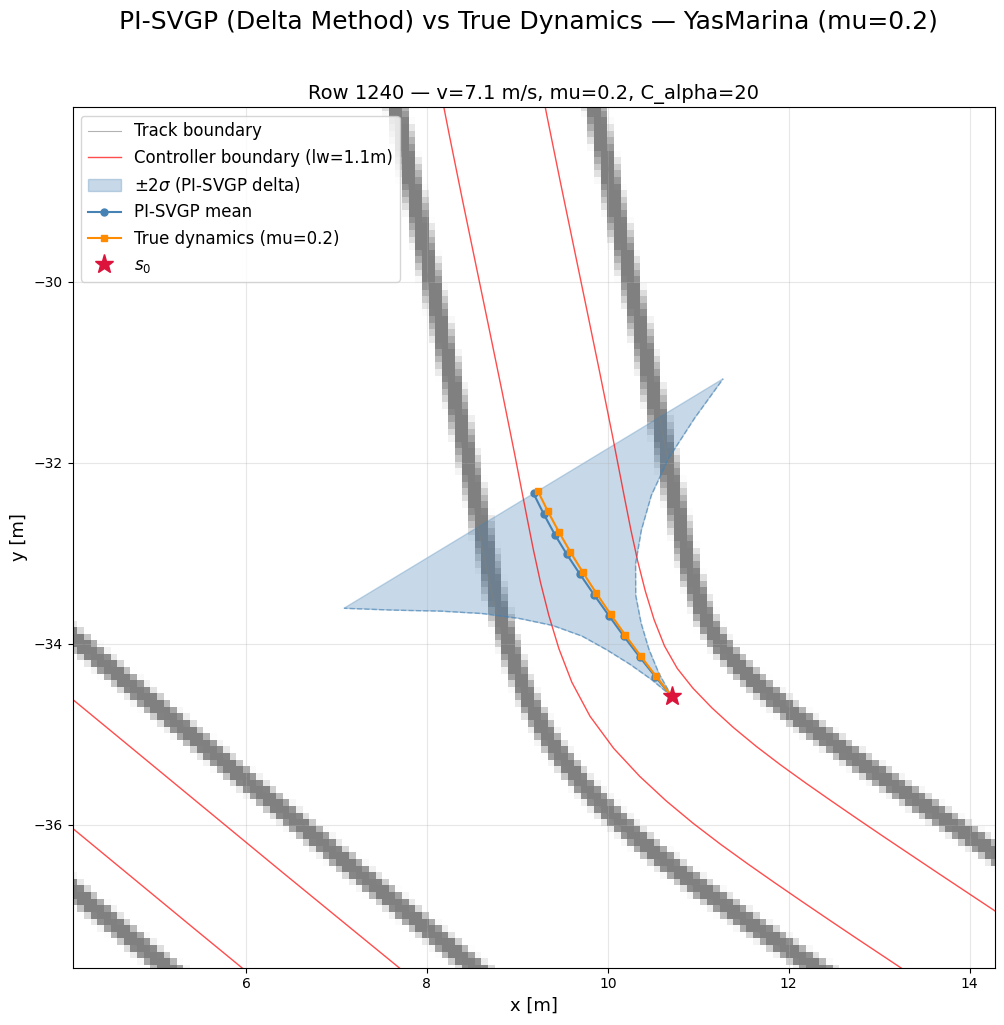

In [14]:
# ── Usage: Same actions (from mu=1.0489 run), change mu to see effect ────────
csv_path = "../results/mcts_pi_svgp_cs_extract_YasMarina_10/traj_config_mcts_dpw_pi_svgp_cpp_cs_extract_s42_YasMarina_10_20260219_110439.csv"
track_name = "YasMarina"
row_indices = [1240 ]

plot_svgp_samples(
    csv_path=csv_path,
    track_name=track_name,
    row_indices=row_indices,
    mu=0.2,       # change to 0.8642 or 0.4947 to see different friction
    lane_width=1.1,
    friction="10489",
    save_dir="plot_res_change_mu_cs",
)